# ACBP equilibrium stability from complete two-dimensional denaturation

This active review reconstructs the full original2020 author workflow: all15 samples,3181 temperatures and both330/350nm channels, totaling95430 observed intensities. The unknown energy surface spans temperature and denaturant concentration rather than spatial coordinates. There is no independent molecular free-energy truth; the original author method provides a reproducibility reference. All18 free optical and thermodynamic parameters are evaluated.

The notebook covers observations, physics and fresh reconstruction, paired thermal/chemical profiles, energy/population surfaces and midpoints, source-postprocessing diagnosis, identifiability/ablations and full-observation perturbation experiments.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import leastsq
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,normalize_intensity,flatten_observations
from src.physics_model import free_energy,unfolded_fraction,baseline_planes,fluorescence,parameter_jacobian
from src.solvers import reconstruct,initial_parameters
from src.main import run
from src.visualization import denaturant_midpoint,relative_l2
t,d,original=load_observations(ROOT/'data/raw_data.npz');y=normalize_intensity(t,original);flat=flatten_observations(t,d,y)
assert y.size==95430 and y.shape==(2,15,3181)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('All original samples',d,'all intensities',y.size)

All original samples [3.01 2.81 2.6  2.41 2.21 2.   1.81 1.6  1.4  1.21 1.   0.8  0.6  0.4
 0.19] all intensities 95430


## 1. Observations and scale

Tryptophan fluorescence changes between folded and unfolded environments. Optical baselines also vary with temperature and chemical concentration, so an intensity curve alone does not directly yield a population. Each measured curve is divided by its own observed value nearest70°C; this observational scale convention has no fitted or hidden calibration. Original processed intensity and all temperatures/concentrations remain public. No curve or point is removed.

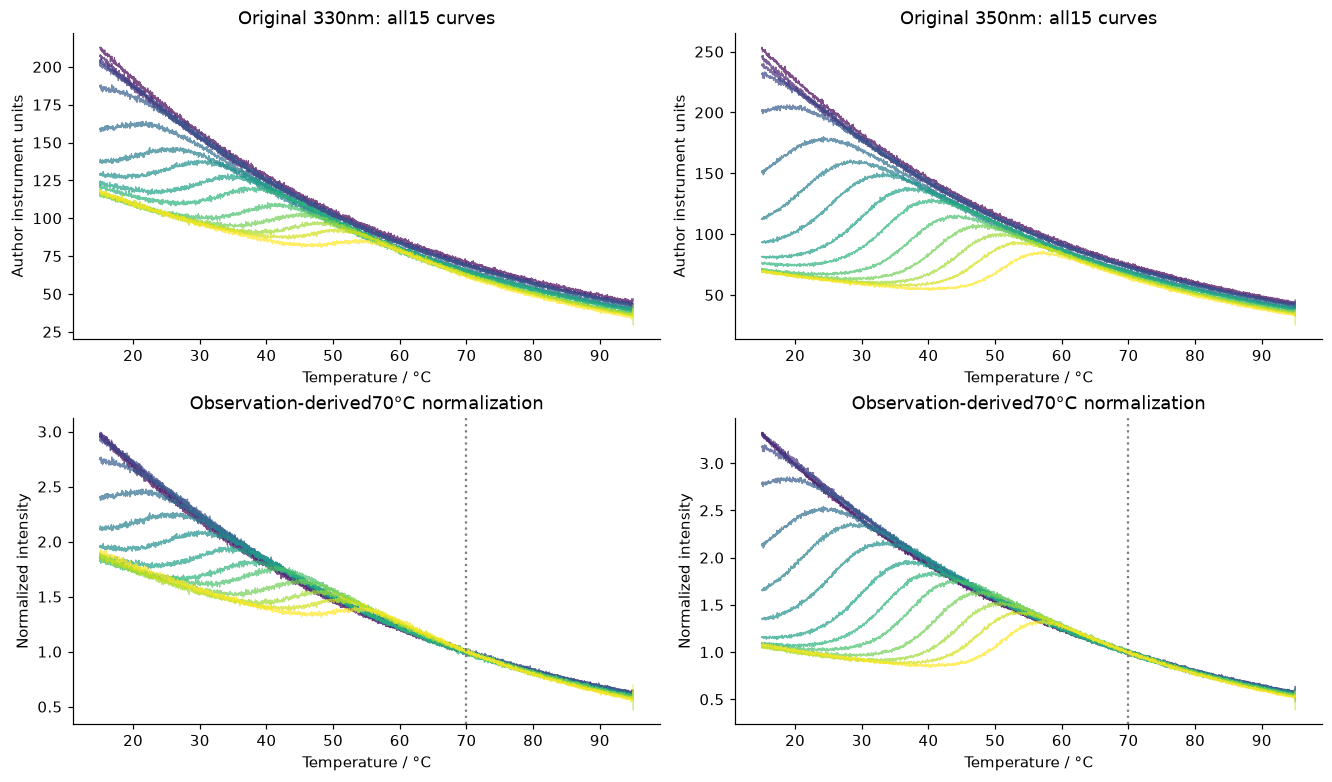

In [2]:
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained');colors=plt.cm.viridis(np.linspace(0,1,15))
for c in range(2):
 for n in range(15):
  ax[0,c].plot(t[n],original[c,n],color=colors[n],alpha=.7,lw=.8)
  ax[1,c].plot(t[n],y[c,n],color=colors[n],alpha=.7,lw=.8)
 ax[0,c].set(xlabel='Temperature / °C',ylabel='Author instrument units',title=f'Original {330+20*c}nm: all15 curves')
 ax[1,c].set(xlabel='Temperature / °C',ylabel='Normalized intensity',title='Observation-derived70°C normalization');ax[1,c].axvline(70,color='gray',ls=':')
plt.show()

## 2. Equilibrium physics and fresh complete reconstruction

Define $T=t+273.15$K, $M=t_m+273.15$K, concentration $D$ in mol/L and $R=0.008314$kJ/(mol K). With enthalpy $H$, heat-capacity change $C$ and denaturant slope $m$, the energy is
$$G=H(1-T/M)+C(T-M-T\log(T/M))-mD.$$
The unfolded population is $u=1/(1+\exp[G/(RT)])$. Each channel has folded plane $F=a_F+b_{FD}D+b_{FT}(t-25)$ and unfolded curved plane $U=a_U+b_{UD}D+b_{UT}(t-25)+b_{UT2}(t-25)^2$. The observation model is $J=(1-u)F+uU$.

The complete global Levenberg–Marquardt least-squares fit starts from the native physical guesses and observed-corner/whole-curve baseline estimates. Both higher-order temperature coefficients of the denaturant slope remain zero. The source precision was independently refined through its own public API before extraction and reference freezing; all three original independent starts converge to the same identifiable18-parameter solution.

Fresh full-fit seconds 0.8597243999829516
tm,H,C,m in declared units [ 53.24023979 375.78540155   5.633575    15.44455629]
{
  "energy_max_abs": 7.500248699443546e-06,
  "thermodynamic_scaled_max_abs": 9.983588455222517e-08,
  "baseline_max_abs": 5.99069243101269e-08,
  "observation_relative_l2": 0.018108853759135998,
  "energy_internal_consistency": 0.0
}


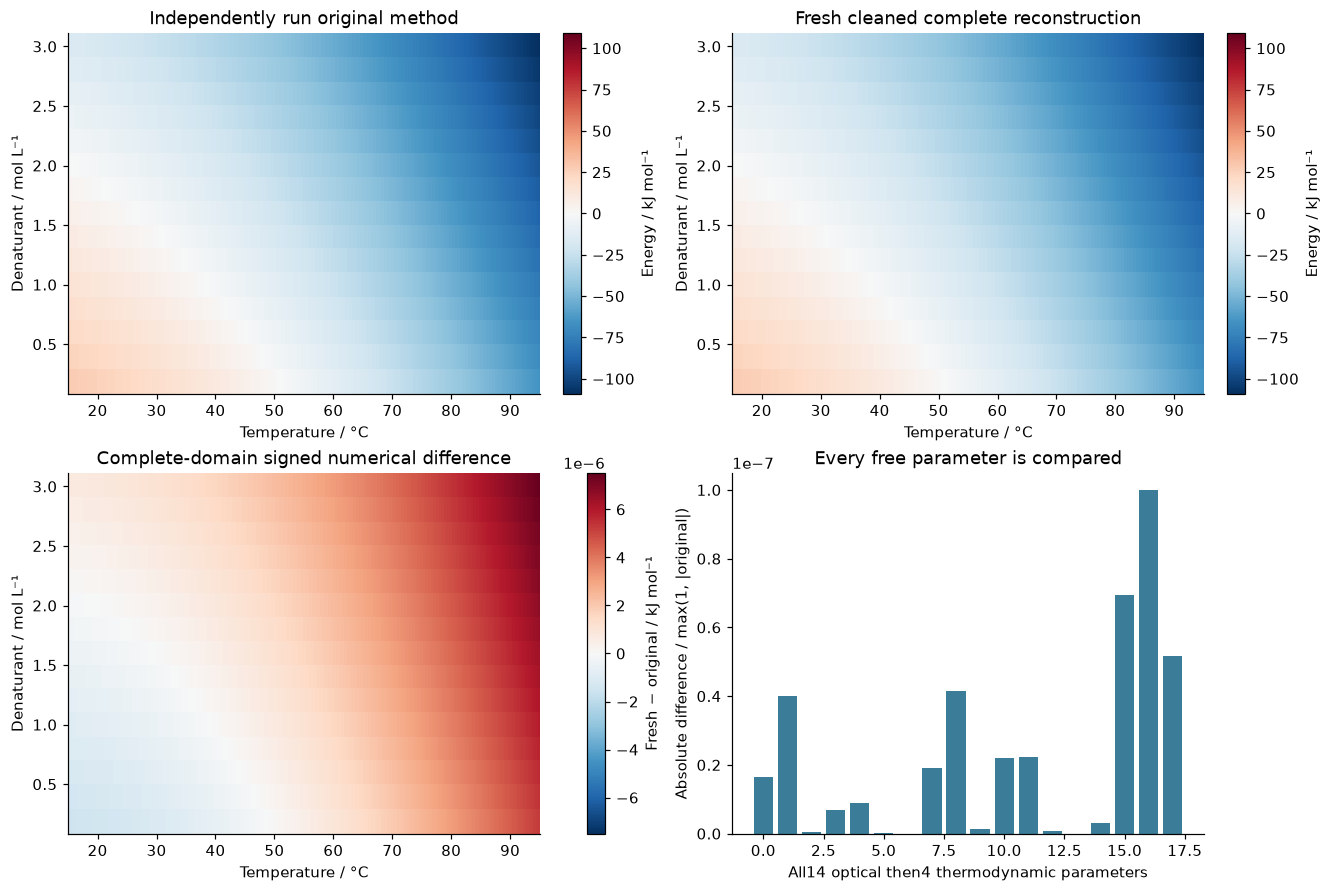

In [3]:
start=time.perf_counter();fit=run();runtime=time.perf_counter()-start;p=fit['parameters'];prediction=fit['prediction'].reshape(y.shape);energy=fit['arrays']['reconstruction'][0];u=unfolded_fraction(t,d[:,None],p[14:18])
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('review_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge);report,status=judge.evaluate(ROOT/'output/reconstruction.npz');assert status==0,report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2));np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_cleaned_standard.npz',**fit['arrays'])
upstream=np.load(ROOT/'notebooks/reference_outputs/upstream_standard.npz')
print('Fresh full-fit seconds',runtime);print('tm,H,C,m in declared units',p[14:18]);print(json.dumps(report['metrics'],indent=2))
fig,ax=plt.subplots(2,2,figsize=(12,8),layout='constrained');order=np.argsort(d);Tcompare=t[order];Dcompare=np.broadcast_to(d[order,None],Tcompare.shape)
source_energy=upstream['reconstruction'][0]
for a,array,title in [(ax[0,0],source_energy,'Independently run original method'),(ax[0,1],energy,'Fresh cleaned complete reconstruction')]:
 im=a.pcolormesh(Tcompare,Dcompare,array[order],shading='auto',cmap='RdBu_r',vmin=-np.max(abs(source_energy)),vmax=np.max(abs(source_energy)));fig.colorbar(im,ax=a,label='Energy / kJ mol⁻¹');a.set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',title=title)
im=ax[1,0].pcolormesh(Tcompare,Dcompare,(energy-source_energy)[order],shading='auto',cmap='RdBu_r',vmin=-np.max(abs(energy-source_energy)),vmax=np.max(abs(energy-source_energy)));fig.colorbar(im,ax=ax[1,0],label='Fresh − original / kJ mol⁻¹');ax[1,0].set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',title='Complete-domain signed numerical difference')
reference_p=np.r_[upstream['baseline_coefficients'].ravel(),upstream['thermodynamic_parameters'].ravel()];parameter_error=abs(p-reference_p)/np.maximum(1,abs(reference_p))
ax[1,1].bar(np.arange(18),parameter_error,color='#3b7c99');ax[1,1].set(xlabel='All14 optical then4 thermodynamic parameters',ylabel='Absolute difference / max(1, |original|)',title='Every free parameter is compared');plt.show()


## 3. Thermal and chemical profiles, full residuals

These plots preserve both wavelength groups and the original notebook's thermal/denaturant comparisons. Every measured thermal point is fitted; the displayed chemical profiles choose fixed15/25/35/45/55°C slices only for visualization. Dashed baseline curves distinguish optical variation from population changes. Residual maps use every measurement and reveal systematic model mismatch; their magnitude is not an independently calibrated noise estimate.

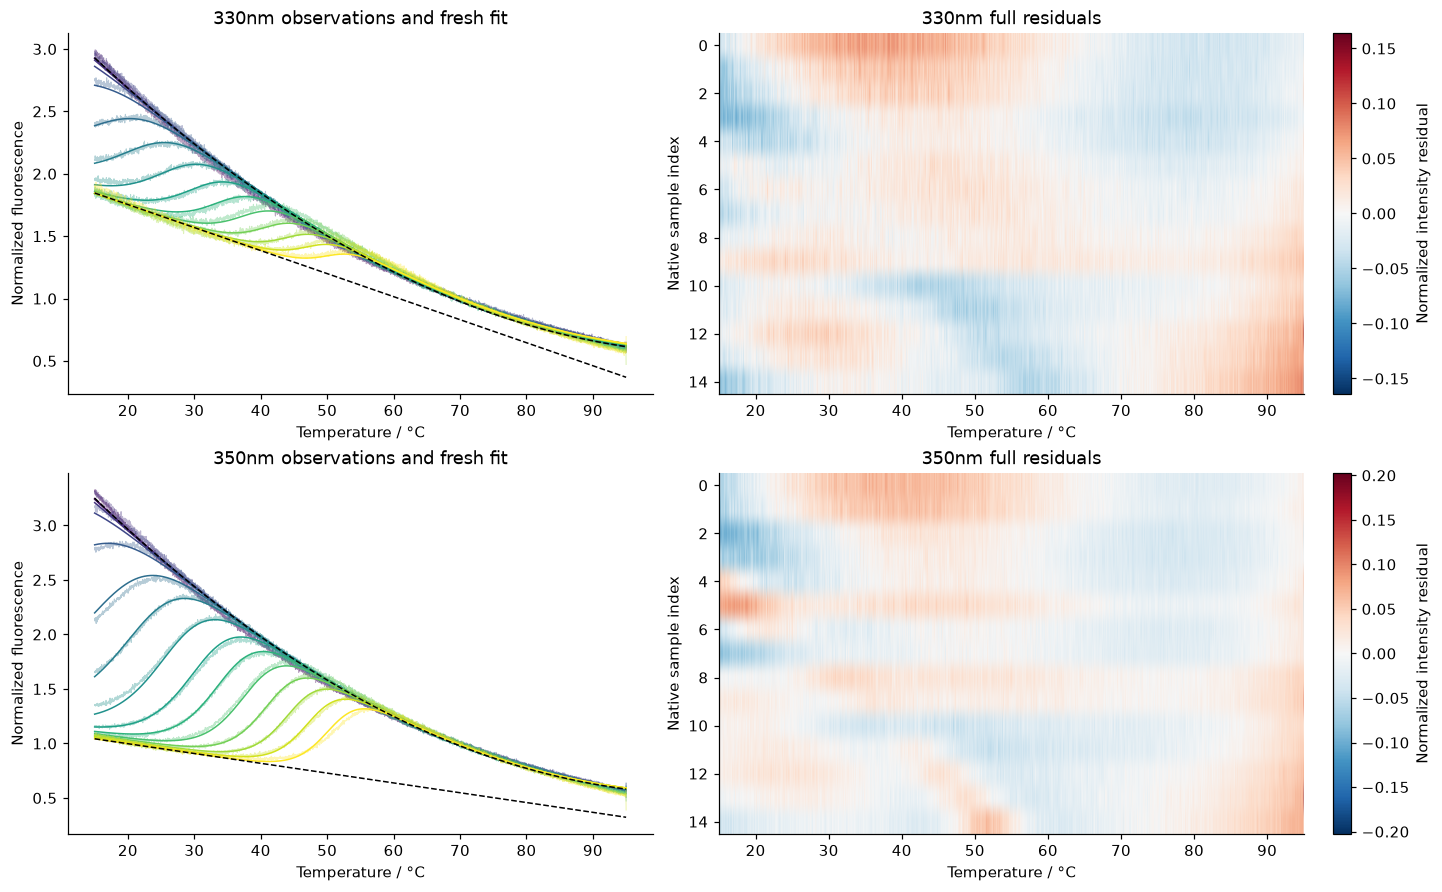

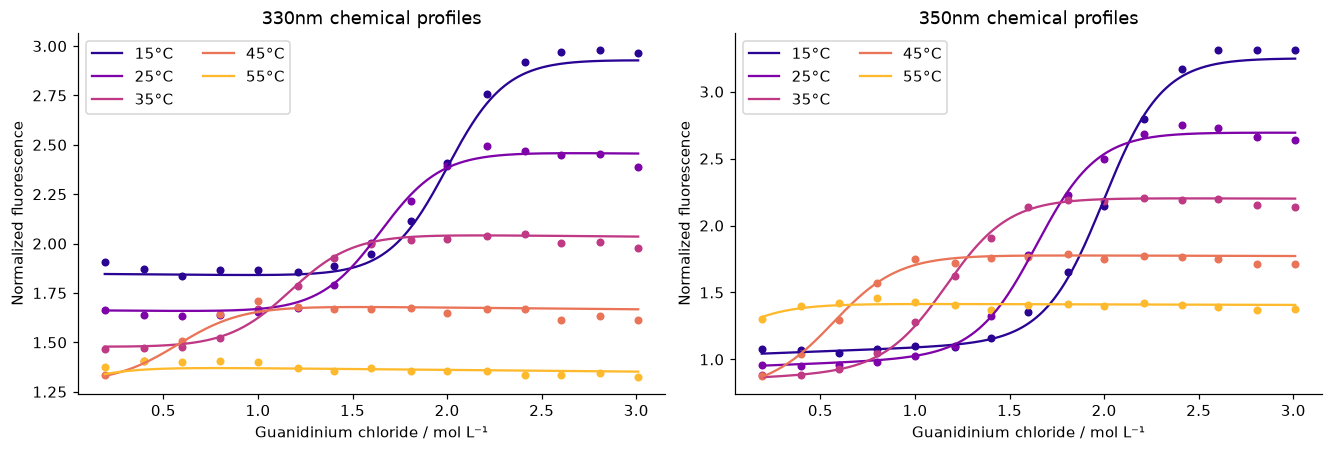

In [4]:
fig,ax=plt.subplots(2,2,figsize=(13,8),layout='constrained')
for c in range(2):
 for n in range(15):
  ax[c,0].plot(t[n],y[c,n],color=colors[n],alpha=.35,lw=.7)
  ax[c,0].plot(t[n],prediction[c,n],color=colors[n],lw=1)
 for n,which in [(int(np.argmin(d)),0),(int(np.argmax(d)),1)]:
  F,U=baseline_planes(t[n],d[n],p[c*7:(c+1)*7]);ax[c,0].plot(t[n],[F,U][which],ls='--',color='black',lw=1)
 ax[c,0].set(xlabel='Temperature / °C',ylabel='Normalized fluorescence',title=f'{330+20*c}nm observations and fresh fit')
 residual=prediction[c]-y[c];im=ax[c,1].imshow(residual,aspect='auto',extent=[15,95,14.5,-.5],cmap='RdBu_r',vmin=-np.max(abs(residual)),vmax=np.max(abs(residual)))
 ax[c,1].set(xlabel='Temperature / °C',ylabel='Native sample index',title=f'{330+20*c}nm full residuals');fig.colorbar(im,ax=ax[c,1],label='Normalized intensity residual')
plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained');fineD=np.linspace(d.min(),d.max(),300)
for c in range(2):
 for temp,color in zip([15,25,35,45,55],plt.cm.plasma(np.linspace(.05,.85,5))):
  index=np.argmin(abs(t-temp),axis=1);ax[c].scatter(d,y[c,np.arange(15),index],s=18,color=color)
  ax[c].plot(fineD,fluorescence(p,np.full(300,temp),fineD,np.full(300,c)),color=color,label=f'{temp}°C')
 ax[c].set(xlabel='Guanidinium chloride / mol L⁻¹',ylabel='Normalized fluorescence',title=f'{330+20*c}nm chemical profiles');ax[c].legend(ncol=2)
plt.show()

## 4. Free-energy/population surfaces and midpoint conditions

The thermal and chemical dimensions jointly determine the energy surface. The midpoint contour has $G=0$, hence $u=1/2$ and $D_{50}(t)=G(t,0)/m$. It is a model-derived equilibrium condition rather than an independent measured truth. The original notebook's surface and midpoint scientific comparisons are retained here with physical energy and population units. The figure's15–95°C domain matches the complete observed temperature range; no extrapolated150°C curve is presented as observed evidence.

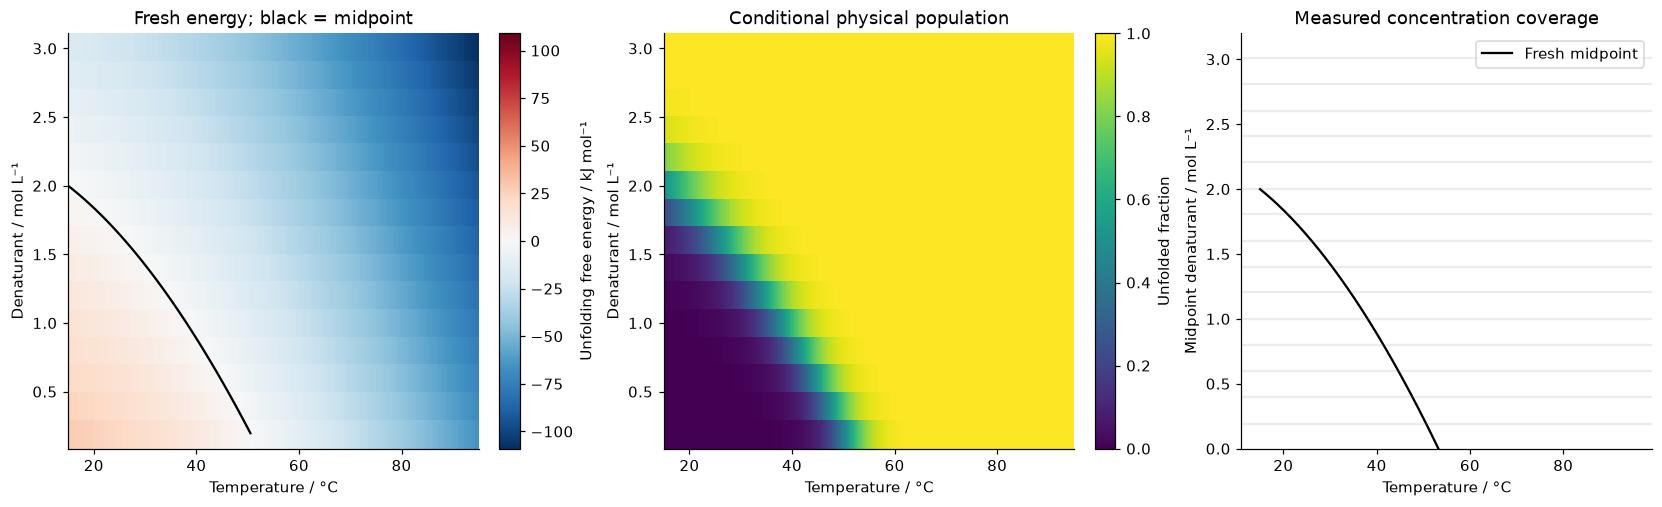

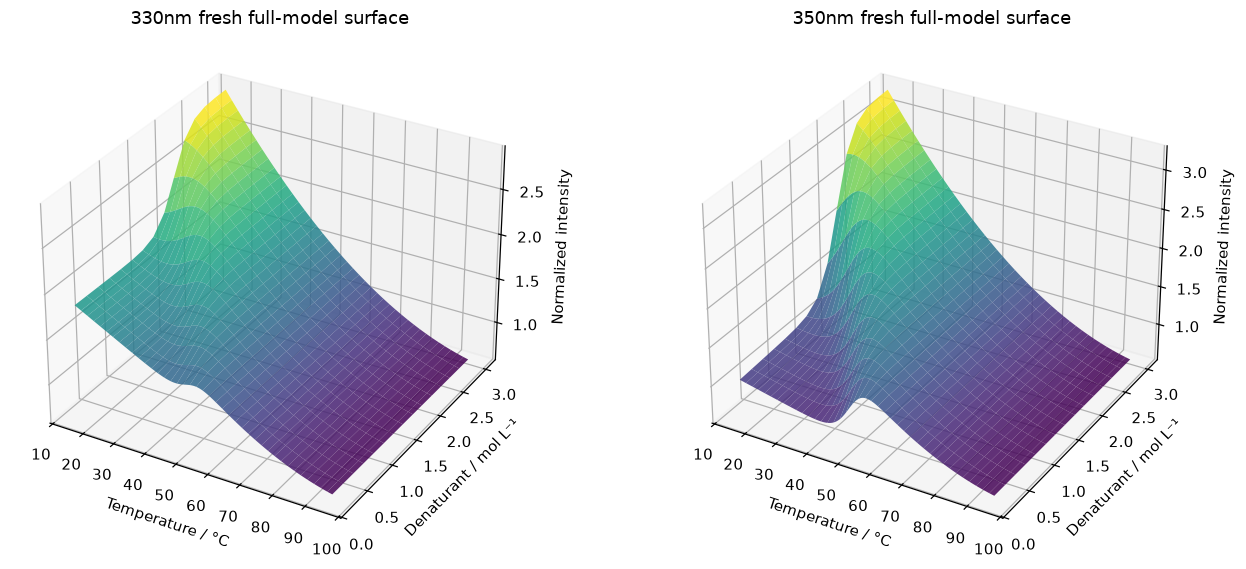

In [5]:
order=np.argsort(d);fig,ax=plt.subplots(1,3,figsize=(15,4.5),layout='constrained');T=t[order];D=np.broadcast_to(d[order,None],T.shape)
im=ax[0].pcolormesh(T,D,energy[order],shading='auto',cmap='RdBu_r',vmin=-np.max(abs(energy)),vmax=np.max(abs(energy)));fig.colorbar(im,ax=ax[0],label='Unfolding free energy / kJ mol⁻¹');ax[0].contour(T,D,energy[order],levels=[0],colors='black');ax[0].set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',title='Fresh energy; black = midpoint')
im=ax[1].pcolormesh(T,D,u[order],shading='auto',vmin=0,vmax=1,cmap='viridis');fig.colorbar(im,ax=ax[1],label='Unfolded fraction');ax[1].set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',title='Conditional physical population')
temp=np.linspace(15,95,500);D50=denaturant_midpoint(temp,p[14:18]);ax[2].plot(temp,D50,color='black',label='Fresh midpoint')
for concentration in d:ax[2].axhline(concentration,color='gray',alpha=.15)
ax[2].set(xlabel='Temperature / °C',ylabel='Midpoint denaturant / mol L⁻¹',ylim=(0,3.2),title='Measured concentration coverage');ax[2].legend();plt.show()
fig=plt.figure(figsize=(12,5),layout='constrained')
for c in range(2):
 ax3=fig.add_subplot(1,2,c+1,projection='3d');ax3.plot_surface(T[:,::20],D[:,::20],prediction[c,order,::20],cmap='viridis',alpha=.85);ax3.set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',zlabel='Normalized intensity',title=f'{330+20*c}nm fresh full-model surface')
plt.show()

## 5. Original postprocessing versus dimensional consistency

The original source notebook's postfit visualization defines a purported normalized population as $J/J^{\mathrm{model}}/(1+\exp G)$. This directly exponentiates dimensional energy and omits division by $RT$; even for exact model observations it disagrees with the equilibrium population. It also does not linearly unmix folded/unfolded baselines. This affects plotting only; the original fitted equilibrium model is correct and unchanged.

We retain this exact legacy diagnostic below and compare it with the validated population $u$ and the algebraically baseline-unmixed observational diagnostic $(J-F)/(U-F)$. The latter is unstable where the baseline contrast is small and is not treated as truth, an estimator input or an evaluation mask. Every point remains in fitting and evaluation. A fixed color range0–1 represents the population scale without clipping any numerical arrays.

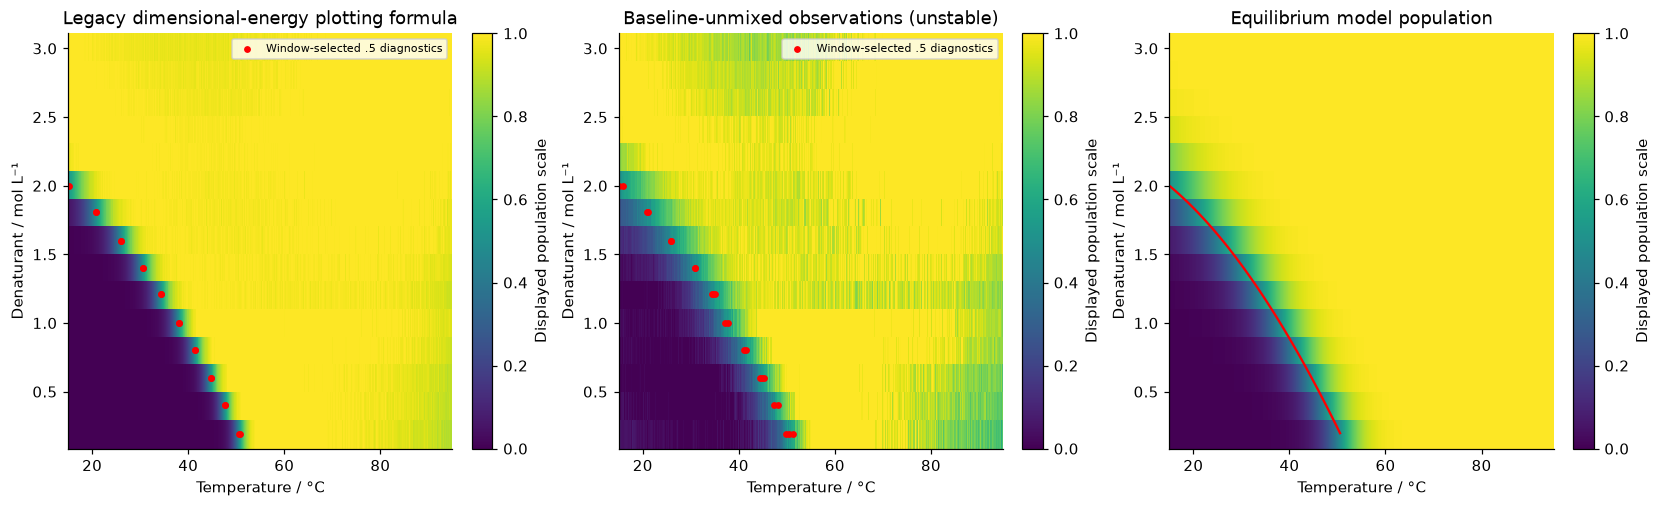

Legacy midpoint annotations 20 baseline-unmixed annotations 23
Legacy-to-physical RMS 0.058194117387593676 minimum absolute optical contrast 0.10784438809083541 unmixed range -0.10228658248810017 1.3996620639712953


In [6]:
legacy=y/prediction/(1+np.exp(energy))[None];unmixed=np.empty_like(y);contrast=np.empty_like(y)
for c in range(2):
 F,U=baseline_planes(t,d[:,None],p[c*7:(c+1)*7]);contrast[c]=U-F;unmixed[c]=(y[c]-F)/(U-F)
assert np.isfinite(unmixed).all()
# Preserve the author's original window-based midpoint annotations explicitly
# as legacy plotting diagnostics, including its source empirical tolerance.
legacy_midpoints=[];unmixed_midpoints=[]
for n in range(15):
 step=t[n,1]-t[n,0]
 for c in range(2):
  for window in np.array_split(np.arange(t.shape[1]),int((t[n,-1]-t[n,0])//5)):
   for array,destination in [(legacy,legacy_midpoints),(unmixed,unmixed_midpoints)]:
    at=int(window[np.argmin(abs(array[c,n,window]-.5))])
    if abs(array[c,n,at]-.5)<step/2:destination.append([float(t[n,at]),float(d[n])])
legacy_midpoints=np.array(legacy_midpoints).reshape(-1,2);unmixed_midpoints=np.array(unmixed_midpoints).reshape(-1,2)
fig,ax=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
for a,array,title in zip(ax,[legacy[0],unmixed[0],u],['Legacy dimensional-energy plotting formula','Baseline-unmixed observations (unstable)','Equilibrium model population']):
 im=a.pcolormesh(T,D,array[order],shading='auto',vmin=0,vmax=1,cmap='viridis');a.set(xlabel='Temperature / °C',ylabel='Denaturant / mol L⁻¹',title=title);fig.colorbar(im,ax=a,label='Displayed population scale')
for a,points in [(ax[0],legacy_midpoints),(ax[1],unmixed_midpoints)]:
 if len(points):a.scatter(points[:,0],points[:,1],s=12,color='red',label='Window-selected .5 diagnostics');a.legend(fontsize=7)
ax[2].contour(T,D,energy[order],levels=[0],colors='red')
plt.show();print('Legacy midpoint annotations',len(legacy_midpoints),'baseline-unmixed annotations',len(unmixed_midpoints));print('Legacy-to-physical RMS' ,np.sqrt(np.mean((legacy-u[None])**2)),'minimum absolute optical contrast',np.min(abs(contrast)),'unmixed range',np.min(unmixed),np.max(unmixed))

## 6. Identifiability, model ablation and observation robustness

Column-normalized sensitivities separate physical identifiability from arbitrary parameter units. Three independent public-derived starts test numerical convergence. Removing heat-capacity change is a nested physical-model ablation fitted on all95430 points; it is not substituted for the complete benchmark. Independent added raw-intensity perturbations then rerun the full native normalization and complete fit. These are numerical sensitivity experiments, not calibrated acquisition-noise uncertainty or95% confidence intervals.

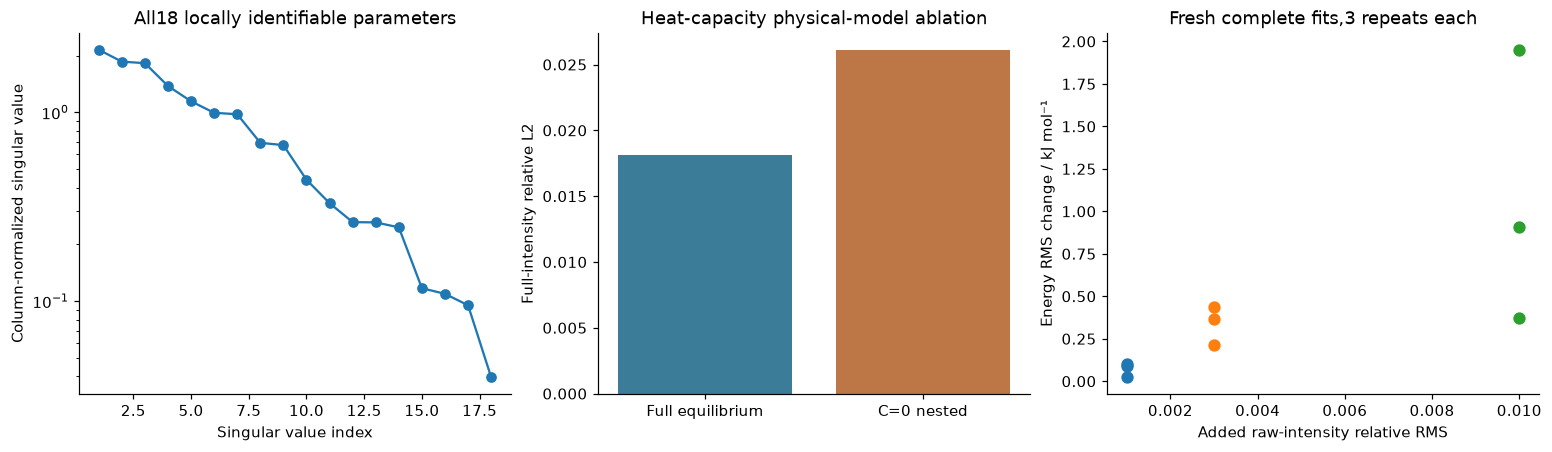

{
  "fresh_runtime_seconds": 0.8597243999829516,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "energy_max_abs": 7.500248699443546e-06,
      "thermodynamic_scaled_max_abs": 9.983588455222517e-08,
      "baseline_max_abs": 5.99069243101269e-08,
      "observation_relative_l2": 0.018108853759135998,
      "energy_internal_consistency": 0.0
    },
    "thresholds": {
      "energy_max_abs": {
        "comparison": "<=",
        "boundary": 0.002
      },
      "thermodynamic_scaled_max_abs": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "baseline_max_abs": {
        "comparison": "<=",
        "boundary": 2e-05
      },
      "observation_relative_l2": {
        "comparison": "<=",
        "boundary": 0.0182
      },
      "energy_internal_consistency": {
        "comparison": "<=",
        "boundary": 1e-06
      }
    },
    "errors": []
  },
  "thermodynamic_parameters": [
    53.24023978571673,
    375.78540154932483,
    5.633

In [7]:
J=parameter_jacobian(p,*flat[:3]);singular=np.linalg.svd(J/np.linalg.norm(J,axis=0),compute_uv=False);assert len(singular)==18 and singular[-1]>.039
starts=[]
for factor in [.93,1.,1.08]:
 f=reconstruct(t,d,y,initial=initial_parameters(t,d,y)*factor);starts.append(dict(factor=factor,objective=f['objective'],thermodynamic=f['parameters'][14:18].tolist()))
# Nested C=0 comparison keeps every observation and all other17 free parameters.
free=np.array([i for i in range(18) if i!=16]);zero_start=p.copy();zero_start[16]=0.
def reduced_residual(q):
 candidate=zero_start.copy();candidate[free]=q;return fluorescence(candidate,*flat[:3])-flat[3]
reduced,cov,info,msg,status=leastsq(reduced_residual,zero_start[free],full_output=True,ftol=1e-12,xtol=1e-12,gtol=1e-12,maxfev=5000);assert status in [1,2,3,4]
no_cp=zero_start.copy();no_cp[free]=reduced;no_cp_l2=relative_l2(fluorescence(no_cp,*flat[:3]),flat[3])
rng=np.random.default_rng(20261026);stress=[]
for scale in [.001,.003,.01]:
 for repeat in range(3):
  disturbed=original+rng.normal(size=original.shape)*scale*np.sqrt(np.mean(original**2,axis=-1,keepdims=True));noisy=normalize_intensity(t,disturbed);f=reconstruct(t,d,noisy);stress.append(dict(scale=scale,repeat=repeat,thermodynamic=f['parameters'][14:18].tolist(),energy_rms_change=float(np.sqrt(np.mean((free_energy(t,d[:,None],f['parameters'][14:18])-energy)**2)))))
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained');ax[0].semilogy(np.arange(1,19),singular,'-o');ax[0].set(xlabel='Singular value index',ylabel='Column-normalized singular value',title='All18 locally identifiable parameters')
ax[1].bar(['Full equilibrium','C=0 nested'],[report['metrics']['observation_relative_l2'],no_cp_l2],color=['#3b7c99','#bd7747']);ax[1].set(ylabel='Full-intensity relative L2',title='Heat-capacity physical-model ablation')
for scale in [.001,.003,.01]:
 values=[r['energy_rms_change'] for r in stress if r['scale']==scale];ax[2].scatter(np.full(3,scale),values,s=50)
ax[2].set(xlabel='Added raw-intensity relative RMS',ylabel='Energy RMS change / kJ mol⁻¹',title='Fresh complete fits,3 repeats each');plt.show()
summary=dict(fresh_runtime_seconds=runtime,judge=report,thermodynamic_parameters=p[14:18].tolist(),jacobian_rank=int(np.linalg.matrix_rank(J/np.linalg.norm(J,axis=0))),jacobian_scaled_min_singular=float(singular[-1]),independent_starts=starts,nested_zero_heat_capacity_relative_l2=no_cp_l2,legacy_population_rms_difference=float(np.sqrt(np.mean((legacy-u[None])**2))),minimum_absolute_optical_contrast=float(np.min(abs(contrast))),stress=stress)
(ROOT/'notebooks/reference_outputs/fresh_review_measurements.json').write_text(json.dumps(summary,indent=2));print(json.dumps({k:v for k,v in summary.items() if k!='stress'},indent=2))

## Conclusion

All15 complete paired thermal curves constrain an identifiable global18-parameter equilibrium solution. The fresh energy surface and all thermodynamic/optical parameters agree with the independently run original method and pass full-observation consistency. The notebook retains the original thermal, chemical, surface and midpoint scientific comparisons, while explicitly diagnosing and replacing only a dimensionally inconsistent postfit plotting formula. Source parity is reproducibility evidence; the measured fluorescence does not provide independently known thermodynamic truth.

Reference: Hamborg et al., *Analytical Biochemistry*605,113863(2020), [doi:10.1016/j.ab.2020.113863](https://doi.org/10.1016/j.ab.2020.113863). Exact source revision, all original captures and unavailable full-paper access details are documented in `test/validation.md`.